Добрый день, это лаба №3, приятного просмотра!

In [34]:
import numpy as np
import pandas as pd
from PIL import Image
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             average_precision_score, roc_auc_score)
from copy import deepcopy
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt

SEED = 42  # Фиксируем случайность, чтобы разбиение воспроизводилось.
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

## 1. Предобработка данных

### 1.1. Загрузка и первичная проверка
Исходную таблицу сохраняем в `raw`: все изменения выполняем в копии.
Нестандартные текстовые обозначения пропусков также считаем пропусками.


In [4]:
# базовый EDA
raw = pd.read_csv('lab_3.csv', na_values=['null', 'NULL', 'None', 'nan', 'NaN', ''])
print('Размер исходных данных:', raw.shape)
print(raw.head().to_string(index=False))
audit = pd.DataFrame({'тип': raw.dtypes.astype(str),
                      'пропуски': raw.isna().sum(),
                      'уникальные': raw.nunique(dropna=True)})
print(audit.to_string())
print('Полных дубликатов:', raw.duplicated().sum())

Размер исходных данных: (8040, 18)
client_id  age   income  employment_years           education region         housing  credit_history_years  n_prev_loans  past_delinquencies  credit_utilization  open_credit_lines  loan_amount  loan_term_months  interest_rate  debt_to_income  collections_contacts  default
CL-206764   42  59627.0               NaN среднее специальное REG-03          аренда                   3.1             1                   0               0.347                  1     266308.0                36          14.53           0.339                     0        0
CL-203188   48 240194.0               1.3              высшее REG-21 у родственников                   1.9             1                   0               0.176                  2     398138.0                24          12.60           0.188                     0        0
CL-204818   46  33394.0               4.2              высшее REG-23         ипотека                   3.8             1                   1      

### 1.2. Единый формат категорий и числовые типы
Удаляем пробелы по краям, повторяющиеся пробелы и различия регистра.
Например, «АРЕНДА», «Аренда» и «аренда » обозначают одну категорию.
Для идентификатора и региона используем верхний регистр. Регион — категория, а не число.
Числа не округляем: это потеря полезной информации, а не необходимая очистка.


In [5]:
# разбираем данные на категории
df = raw.copy()
categorical_cols = ['education', 'region', 'housing']
target = 'default'
numeric_source = [c for c in df.columns if c not in categorical_cols + ['client_id']]

for col in ['client_id'] + categorical_cols:
    s = df[col].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    s = s.str.upper() if col in ['client_id', 'region'] else s.str.lower()
    s = s.mask(s.str.lower().isin(['', 'nan', 'null', 'none']))
    df[col] = s.astype(object).where(s.notna(), np.nan)

for col in numeric_source:
    df[col] = pd.to_numeric(df[col], errors='coerce').replace([np.inf, -np.inf], np.nan)

print('Категорий housing до:', raw.housing.nunique(), '| после:', df.housing.nunique())
print(df.housing.value_counts(dropna=False).to_string())


Категорий housing до: 11 | после: 4
housing
аренда             2813
собственное        2232
ипотека            1955
у родственников    1040


### 1.3. Дубликаты, идентификатор и целевая переменная
Полные дубликаты удаляем **до разбиения**, иначе одна заявка может попасть и в обучение, и в тест.
Если после этого остаются разные строки одного клиента, не выбираем одну произвольно:
потребуется разбор повторных заявок и разбиение по группам клиентов.
Целевую переменную не заполняем медианой или модой. Строки без корректной метки
не подходят для обучения с учителем и сохраняются отдельно.


In [6]:
n_before = len(df)
df = df.drop_duplicates().copy()
print('Удалено полных дубликатов:', n_before - len(df))
bad_labels = ~df[target].isin([0, 1])
unlabeled_rows = df.loc[bad_labels].copy()
df = df.loc[~bad_labels].copy()
print('Строк с отсутствующей/некорректной целью:', len(unlabeled_rows))
if df.client_id.isna().any():
    raise ValueError('Есть строки без client_id: необходим разбор идентификаторов.')
if df.client_id.duplicated().any():
    raise ValueError('Есть разные записи одного клиента: используйте групповое разбиение.')
df[target] = df[target].astype('int64')
df = df.reset_index(drop=True)
print('После удаления дубликатов и проверки цели:', df.shape)


Удалено полных дубликатов: 40
Строк с отсутствующей/некорректной целью: 0
После удаления дубликатов и проверки цели: (8000, 18)


### 1.4. Проверка допустимых значений и выбросов
Явно недопустимые значения заменяем пропусками, чтобы затем заполнить их по обучающим данным.
Используем только простые смысловые ограничения: доход и сумма кредита положительны,
стаж и счётчики неотрицательны, возраст положителен и не превышает 120 лет.
Это технические проверки, а не правила кредитной политики.

Долговая нагрузка или использование лимита выше 1 не обязательно ошибка, поэтому
верхнюю границу 1 автоматически не применяем. Большой доход или кредит также не
являются доказательством ошибки: экстремальные значения сохраняем, используем
устойчивое масштабирование. Стаж и кредитную историю больше возраста отмечаем для проверки.


In [8]:
invalid_counts = {}
positive = ['income', 'loan_amount', 'loan_term_months', 'interest_rate']
nonnegative = ['employment_years', 'credit_history_years', 'n_prev_loans',
               'past_delinquencies', 'credit_utilization', 'open_credit_lines',
               'debt_to_income', 'collections_contacts']
integer_cols = ['age', 'n_prev_loans', 'past_delinquencies',
                'open_credit_lines', 'loan_term_months', 'collections_contacts']
# сравниваем построчно каждый с каждым
for col in numeric_source:
    if col == target:
        continue
    bad = pd.Series(False, index=df.index)
    if col in positive:
        bad |= df[col].le(0)
    if col in nonnegative:
        bad |= df[col].lt(0)
    if col == 'age':
        bad |= df[col].le(0) | df[col].gt(120)
    if col in integer_cols:
        bad |= df[col].notna() & df[col].mod(1).ne(0)
    invalid_counts[col] = int(bad.sum())
    df.loc[bad, col] = np.nan

print('Заменено недопустимых значений:', invalid_counts)
print('Стаж больше возраста:', int(df.employment_years.gt(df.age).sum()))
print('Кредитная история больше возраста:', int(df.credit_history_years.gt(df.age).sum()))
print(df[['income', 'loan_amount', 'employment_years']].describe(
    percentiles=[0.5, 0.95, 0.99]).round(2).to_string())
print('Пропуски после очистки:')
print(df.isna().sum()[lambda s: s > 0].to_string())


Заменено недопустимых значений: {'age': 0, 'income': 0, 'employment_years': 0, 'credit_history_years': 0, 'n_prev_loans': 0, 'past_delinquencies': 0, 'credit_utilization': 0, 'open_credit_lines': 0, 'loan_amount': 0, 'loan_term_months': 0, 'interest_rate': 0, 'debt_to_income': 0, 'collections_contacts': 0}
Стаж больше возраста: 0
Кредитная история больше возраста: 0
           income  loan_amount  employment_years
count     7681.00      8000.00           7720.00
mean     72508.19    387334.88              5.07
std      43701.00    266727.83              3.65
min      18000.00     35986.00              0.00
50%      64929.00    318060.00              4.40
95%     135756.00    878035.65             12.00
99%     189973.20   1353192.69             16.50
max    1269680.00   4201258.00             24.90
Пропуски после очистки:
income              319
employment_years    280


### 1.5. Предотвращение утечки целевой переменной

| Поле | Решение | Причина |
|---|---|---|
| `default` | Только `y` | Это результат, который предсказываем |
| `client_id` | Сохранить для контроля, исключить из `X` | Идентификатор клиента |
| `collections_contacts` | Исключить из `X` | Контакты взыскания могут возникать после выдачи и отражать последствия дефолта |
| `interest_rate` | По умолчанию исключить из `X` | Неизвестно, известна ли ставка до решения или назначается после скоринга |
| Остальные поля | Кандидаты в `X` | Предполагаем, что это сведения на момент заявки |

Словаря данных и временных меток нет, поэтому происхождение `collections_contacts`
не доказано. Консервативно исключаем поле до подтверждения, что оно относится только
к прошлой истории и доступно до решения. Также нужно подтвердить, что `loan_amount`
и `loan_term_months` — запрошенные, а не окончательно назначенные параметры.
Сильная связь сама по себе не доказывает утечку; важен момент появления информации.


In [9]:
# True — только после подтверждения происхождения ставки.
RATE_KNOWN_BEFORE_DECISION = False
excluded = ['client_id', 'collections_contacts', target]
if not RATE_KNOWN_BEFORE_DECISION:
    excluded.append('interest_rate')
X = df.drop(columns=excluded).copy()
y = df[target].copy()
client_ids = df['client_id'].copy()
print('Исключены из X:', excluded)
print('Осталось исходных признаков:', X.shape[1])


Исключены из X: ['client_id', 'collections_contacts', 'default', 'interest_rate']
Осталось исходных признаков: 14


### 1.6. Разбиение 60% / 20% / 20% с сохранением доли дефолтов
Сначала разбиваем данные, затем учим заполнение пропусков и масштабирование.
`stratify=y` сохраняет долю редкого класса. Проверочная выборка (`valid`) нужна для
выбора модели и порога, тестовая (`test`) — для однократной итоговой оценки.
Даты заявок отсутствуют, поэтому временное разбиение выполнить нельзя.
Для проверки на будущих заявках впоследствии нужна отдельная временная выборка.


In [11]:
# Выборка test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=SEED, stratify=y)
# Выборка valid
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

split_summary = pd.DataFrame([
    {'выборка': name, 'строк': len(labels), 'дефолтов': int(labels.sum()),
     'доля дефолтов': labels.mean()}
    for name, labels in [('train', y_train), ('valid', y_valid), ('test', y_test)]
])

print(split_summary.to_string(index=False))
print(f'Дефолтов во всём очищенном наборе: {y.sum()} из {len(y)} ({y.mean():.2%})')
print(f'Accuracy прогноза «все надёжные»: {1 - y.mean():.2%}; recall дефолта = 0%.')

выборка  строк  дефолтов  доля дефолтов
  train   4800       325       0.067708
  valid   1600       109       0.068125
   test   1600       108       0.067500
Дефолтов во всём очищенном наборе: 542 из 8000 (6.78%)
Accuracy прогноза «все надёжные»: 93.23%; recall дефолта = 0%.


### 1.7. Конвейер предобработки
**Числа:** медиана обучающей выборки заполняет пропуски; индикаторы отсутствия значения
сохраняют информацию о пропусках; `RobustScaler` использует медиану и межквартильный размах.
Он уменьшает влияние экстремальных значений на масштаб, но не удаляет и не обрезает их.

**Категории:** пропуски становятся отдельной категорией; One-Hot Encoding создаёт
бинарные признаки без искусственного порядка. Неизвестные категории в новых данных
не приводят к ошибке (`handle_unknown='ignore'`).

`fit_transform` вызываем только для train, для valid/test — исключительно `transform`.
На этапе предобработки редкий класс сохраняем. Балансировку сравниваем отдельно в разделе 5, только на train. При кросс-валидации весь конвейер нужно обучать внутри каждого фолда.


In [12]:
cat_features = [c for c in categorical_cols if c in X_train.columns]
num_features = [c for c in X_train.columns if c not in cat_features]
if X_train[num_features].isna().all().any():
    raise ValueError('Есть полностью пустой числовой признак в train: нужен отдельный разбор.')

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', RobustScaler()),
])
# Совместимость с выпусками sklearn до переименования sparse в sparse_output.
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='неизвестно')),
    ('encoder', encoder),
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_features),
    ('cat', categorical_pipeline, cat_features),
], remainder='drop')

train_array = preprocessor.fit_transform(X_train)
valid_array = preprocessor.transform(X_valid)
test_array = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
X_train_ready = pd.DataFrame(train_array, index=X_train.index, columns=feature_names)
X_valid_ready = pd.DataFrame(valid_array, index=X_valid.index, columns=feature_names)
X_test_ready = pd.DataFrame(test_array, index=X_test.index, columns=feature_names)
print('Размеры готовых матриц:', X_train_ready.shape, X_valid_ready.shape, X_test_ready.shape)
print('Медианы, рассчитанные только на train:')
print(pd.Series(preprocessor.named_transformers_['num'].named_steps['imputer'].statistics_,
                index=num_features).round(3).to_string())

Размеры готовых матриц: (4800, 49) (1600, 49) (1600, 49)
Медианы, рассчитанные только на train:
age                         38.000
income                   64441.000
employment_years             4.300
credit_history_years         3.350
n_prev_loans                 2.000
past_delinquencies           0.000
credit_utilization           0.340
open_credit_lines            2.000
loan_amount             317835.000
loan_term_months            36.000
debt_to_income               0.422


### 1.8. Контроль результата
Проверяем отсутствие пропусков и бесконечностей, совпадение порядка признаков,
соответствие `X` и `y`, отсутствие пересечений клиентов между выборками и утечек в `X`.


In [15]:
for prepared, labels in [(X_train_ready, y_train), (X_valid_ready, y_valid), (X_test_ready, y_test)]:
    assert prepared.index.equals(labels.index)
    assert np.isfinite(prepared.to_numpy()).all()
    assert prepared.columns.equals(X_train_ready.columns)
train_ids = set(client_ids.loc[X_train.index])
valid_ids = set(client_ids.loc[X_valid.index])
test_ids = set(client_ids.loc[X_test.index])
assert train_ids.isdisjoint(valid_ids)
assert train_ids.isdisjoint(test_ids)
assert valid_ids.isdisjoint(test_ids)
assert len(X_train) + len(X_valid) + len(X_test) == len(df)
assert not set(excluded).intersection(X.columns)
# ошибок не выдало, значит всё шик

### 1.9. Связь с бизнес-задачей: базовое правило и цена ошибок
`1` в решении означает отказ, `0` — одобрение. Поэтому:

- **FN:** одобрили клиента с дефолтом; стоимость 8.
- **FP:** отказали надёжному клиенту; стоимость 1.
- **Суммарная стоимость:** `8 × FN + FP` в условных единицах.

Считаем исходное правило только на **train**, оставляя test для последующей итоговой оценки.
Пропуски в полях правила не считаем автоматически одобрением: такие заявки требуют проверки.
Для сравнения с моделью позднее используйте ту же выборку и те же правила учёта пропусков.


In [19]:
def decision_metrics(y_true, reject):
# labels фиксирует порядок классов, даже если прогноз состоит из одного класса.
    tn, fp, fn, tp = confusion_matrix(y_true, reject, labels=[0, 1]).ravel()
    return {'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
            'precision': precision_score(y_true, reject, zero_division=0),
            'recall': recall_score(y_true, reject, zero_division=0),
            'F1': f1_score(y_true, reject, zero_division=0),
            'cost_8FN_FP': int(8 * fn + fp),
            'cost_per_application': (8 * fn + fp) / len(y_true),
            'rejection_rate': float(np.mean(reject))}

rule_inputs = X_train[['debt_to_income', 'past_delinquencies']]
complete = rule_inputs.notna().all(axis=1)
rule_reject = ((rule_inputs.loc[complete, 'debt_to_income'] > 0.5) |
               (rule_inputs.loc[complete, 'past_delinquencies'] >= 2)).astype(int)
print('Заявок train, требующих проверки из-за пропусков:', int((~complete).sum()))
print(pd.Series(decision_metrics(y_train.loc[complete], rule_reject)).to_string())

Заявок train, требующих проверки из-за пропусков: 0
TN                      2445.000000
FP                      2030.000000
FN                        12.000000
TP                       313.000000
precision                  0.133589
recall                     0.963077
F1                         0.234633
cost_8FN_FP             2126.000000
cost_per_application       0.442917
rejection_rate             0.488125


### 1.10. Переход к моделированию
Матрицы `X_train_ready`, `X_valid_ready`, `X_test_ready` готовы для прямого обучения.
В разделе 2 для кросс-валидации используем исходный `X_train` и полный конвейер:
предобработка и отбор заново обучаются внутри каждого фолда.
В разделах 5–7 используем один набор признаков, выбранный только по train,
чтобы сравнить влияние способов балансировки при неизменных входных признаках.

В выгрузке отсутствуют даты и описание горизонта дефолта. Также неизвестно,
откуда получены исходы по ранее отклонённым заявкам: это ограничивает выводы о будущих решениях банка.


## 2. Отбор признаков: метод и защита от утечки
До статистического отбора мы уже исключили идентификатор, цель и потенциальные утечки.
Теперь используем `SelectKBest(f_classif)`: он оценивает различия каждого признака между
клиентами с дефолтом и без него и сохраняет `k` признаков с наибольшей F-статистикой.
Отбор выполняется **после** заполнения пропусков и One-Hot Encoding, поэтому отдельная
категория, например один регион, считается отдельным признаком.

Число признаков выбираем из 10, 20, 30 и всех признаков по среднему **Average Precision (AP)**
на 5 стратифицированных фолдах внутри train. AP характеризует качество ранжирования
редкого положительного класса; её ориентир для неинформативного ранжирования — доля дефолтов.
AP и трапецеидальная площадь под PR-кривой — не строго одна и та же величина.

В каждом фолде заново обучаются предобработка, отбор и логистическая регрессия.
Матрицы `X_train_ready` для этой кросс-валидации не используем: иначе медианы,
масштабы и категории уже были бы рассчитаны с участием внутренних проверочных фолдов.
Метод простой и однофакторный: он не учитывает взаимодействия и дублирование информации.
F-оценки используем как критерий ранжирования, а не доказательство причинного влияния.


In [20]:
# Данные и метки должны соответствовать одной версии очищенной таблицы.
assert X_train.index.equals(y_train.index), 'Перезапустите ядро и выполните все ячейки по порядку.'
assert X_train.index.intersection(X_valid.index).empty
assert X_train.index.intersection(X_test.index).empty
# clone удаляет обученное состояние, назовём это функцией обнуления
model_pipeline = Pipeline([
    ('preprocess', clone(preprocessor)),  
    ('select', SelectKBest(score_func=f_classif)),
    ('model', LogisticRegression(C=1.0, max_iter=3000, random_state=SEED)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(
    estimator=model_pipeline,
    param_grid={'select__k': [10, 20, 30, 'all']},
    scoring='average_precision',
    cv=cv,
    n_jobs=1,
    refit=True,           
    error_score='raise',
)
# Лучший вариант заново обучается на всём train. Ошибки выполнения не маскируются значением NaN(а будет остановлена программа)
search.fit(X_train, y_train)
logreg = search.best_estimator_

cv_table = pd.DataFrame({
    'число признаков': search.cv_results_['param_select__k'].astype(str),
    'средний AP': search.cv_results_['mean_test_score'],
    'std AP по фолдам': search.cv_results_['std_test_score'],
    'место': search.cv_results_['rank_test_score'],
}).sort_values('место')
print(cv_table.round(4).to_string(index=False))
print('Выбранное k:', search.best_params_['select__k'])


число признаков  средний AP  std AP по фолдам  место
             10      0.2768            0.0531      1
            all      0.2666            0.0521      2
             20      0.2646            0.0554      3
             30      0.2615            0.0528      4
Выбранное k: 10


### 2.1. Какие признаки оставлены
Таблица показывает F-оценку и результат отбора для каждого подготовленного признака.
Префикс `num__` обозначает числовой признак, `cat__` — категорию после кодирования.
Коэффициенты выбранной логистической регрессии показываем отдельно:
положительный коэффициент повышает логарифм шансов дефолта при прочих равных,
отрицательный — снижает. Их абсолютные величины нельзя напрямую трактовать как
универсальную важность: числовые и бинарные признаки имеют разные масштабы.


In [21]:
prepared_names = logreg.named_steps['preprocess'].get_feature_names_out()
selector = logreg.named_steps['select']
support = selector.get_support()
feature_selection = pd.DataFrame({
    'признак': prepared_names,
    'F-оценка': selector.scores_,
    'оставлен': support,
}).sort_values('F-оценка', ascending=False)
print(feature_selection.round(4).to_string(index=False))
selected_features = prepared_names[support]
coefficients = pd.DataFrame({
    'признак': selected_features,
    'коэффициент': logreg.named_steps['model'].coef_[0],
}).sort_values('коэффициент', ascending=False)
print(f'\nОставлено {len(selected_features)} из {len(prepared_names)} признаков:')
print(coefficients.round(4).to_string(index=False))


                               признак  F-оценка  оставлен
                   num__debt_to_income  379.3572      True
               num__past_delinquencies  138.6139      True
                 num__loan_term_months   91.1411      True
                           num__income   73.7229      True
                      num__loan_amount   60.8056      True
               num__credit_utilization   16.2127      True
                    cat__region_REG-08    3.6067      True
             num__credit_history_years    3.3071      True
                    cat__region_REG-19    2.9165      True
                     num__n_prev_loans    2.6718      True
                    cat__region_REG-21    2.5122     False
              cat__housing_собственное    2.4675     False
                cat__education_среднее    2.3969     False
                 num__employment_years    2.2565     False
          num__missingindicator_income    2.2444     False
                              num__age    2.0763     Fal

## 3. Базовая модель и точка отсчёта. Логистическая регрессия
Логистическая регрессия оценивает `p(default = 1 | X)` через логистическую функцию от линейной
комбинации признаков. Используем L2-регуляризацию, `C=1`, максимум 3000 итераций.
Модель `logreg` уже обучена на train в разделе 2 с выбранным числом признаков.
Контрольная `logreg_all` использует все допустимые признаки.

Сравниваем на одной validation три типа решений: «одобрить всех», действующее правило
`debt_to_income > 0.5 или past_delinquencies >= 2` и логистическую регрессию при пороге 0.5.
Действующее правило и наивная стратегия не обучаются. Для всех решений используются одинаковые метрики.
Validation служит для разработки; итоговое сравнение на test находится в разделе 6.


In [22]:
# Точка отсчёта без статистического отбора признаков.
logreg_all = clone(model_pipeline).set_params(select__k='all')
logreg_all.fit(X_train, y_train)

def full_metrics(y_true, reject, scores):
    result = decision_metrics(y_true, reject)
    result.update({
        'accuracy': accuracy_score(y_true, reject),
        'balanced_accuracy': balanced_accuracy_score(y_true, reject),
        'ROC_AUC': roc_auc_score(y_true, scores),
        'AP': average_precision_score(y_true, scores),
        'approval_rate': 1 - float(np.mean(reject)),
    })
    return result

def current_rule(frame):
    required = frame[['debt_to_income', 'past_delinquencies']]
    if required.isna().any().any():
        raise ValueError('В полях правила есть пропуски: заранее определите порядок ручной проверки.')
    return ((frame['debt_to_income'] > 0.5) |
            (frame['past_delinquencies'] >= 2)).astype(int).to_numpy()

def print_comparison(table):
    quality = ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'F1', 'ROC_AUC', 'AP']
    business = ['TN', 'FP', 'FN', 'TP', 'cost_8FN_FP', 'cost_per_application', 'approval_rate']
    print('Качество (доли от 0 до 1):')
    print(table[quality].round(4).to_string())
    print('\nОшибки и экономика (доля одобрений — от 0 до 1):')
    print(table[business].round(4).to_string())

valid_rule = current_rule(X_valid)
valid_prob_base = logreg.predict_proba(X_valid)[:, 1]
valid_prob_all = logreg_all.predict_proba(X_valid)[:, 1]
zero_valid = np.zeros(len(y_valid), dtype=int)
baseline_comparison = pd.DataFrame.from_dict({
    'Одобрить всех': full_metrics(y_valid, zero_valid, zero_valid),
    'Действующее правило': full_metrics(y_valid, valid_rule, valid_rule),
    'ЛР: все признаки, 0.5': full_metrics(y_valid, valid_prob_all >= 0.5, valid_prob_all),
    'ЛР: отбор, 0.5': full_metrics(y_valid, valid_prob_base >= 0.5, valid_prob_base),
}, orient='index')
print('Базовое сравнение на validation:')
print_comparison(baseline_comparison)


Базовое сравнение на validation:
Качество (доли от 0 до 1):
                       accuracy  balanced_accuracy  precision  recall      F1  ROC_AUC      AP
Одобрить всех            0.9319             0.5000     0.0000  0.0000  0.0000   0.5000  0.0681
Действующее правило      0.5850             0.7646     0.1382  0.9725  0.2420   0.7646  0.1363
ЛР: все признаки, 0.5    0.9362             0.5406     0.8182  0.0826  0.1500   0.8649  0.3679
ЛР: отбор, 0.5           0.9344             0.5269     0.7500  0.0550  0.1026   0.8696  0.3889

Ошибки и экономика (доля одобрений — от 0 до 1):
                         TN   FP   FN   TP  cost_8FN_FP  cost_per_application  approval_rate
Одобрить всех          1491    0  109    0          872                0.5450         1.0000
Действующее правило     830  661    3  106          685                0.4281         0.5206
ЛР: все признаки, 0.5  1489    2  100    9          802                0.5012         0.9931
ЛР: отбор, 0.5         1489    2  103    6 

## 4. Выбор метрики и обоснование
**Основная метрика для выбора решения банка — средняя стоимость ошибки:**

\[
L = \frac{8\,FN + FP}{N} \quad\longrightarrow\quad \min.
\]

При фиксированном размере выборки это эквивалентно минимуму суммарной стоимости
`8 × FN + FP`. Среднюю стоимость удобнее сравнивать между выборками разного размера.
Восемь — относительная цена пропущенного дефолта из условия, а не произвольно выбранный вес класса.

| Метрика | Что показывает | Роль в работе |
|---|---|---|
| Стоимость `8 × FN + FP` и стоимость на заявку | Компромисс между потерей тела кредита и упущенной прибылью | Основной критерий выбора подхода и порога на validation |
| Average Precision (AP) | Качество ранжирования редкого класса через precision–recall | Критерий отбора числа признаков внутри train, дополнительная оценка качества |
| Recall = TP / (TP + FN) | Доля найденных дефолтов | Контроль пропущенных рискованных клиентов |
| Precision = TP / (TP + FP) | Доля дефолтов среди отказов | Контроль необоснованных отказов |
| F1 | Баланс precision и recall | Дополнительная метрика; не учитывает цену ошибок 8:1 |
| Balanced accuracy | Среднее recall дефолтов и надёжных клиентов | Не позволяет большому классу полностью определять оценку |
| ROC AUC | Качество ранжирования пары «дефолт / без дефолта» | Дополнительная метрика; не задаёт цену FP/FN |
| Accuracy | Доля правильных решений | Только справочно: «одобрить всех» уже даёт около 93% |
| Доля одобрений | Доля клиентов, получивших кредит | Бизнес-показатель, оценивается вместе со стоимостью и recall |

**Почему не только recall?** Отказав всем, можно получить recall = 1, но потерять всех надёжных клиентов.
**Почему не только F1 или AP?** Они полезны при дисбалансе, однако не включают заданную цену 8:1.
AP используется для предварительного отбора признаков до выбора порога; это вспомогательный критерий,
который не гарантирует глобально минимальную стоимость банковских решений.

ROC AUC и AP модели считаем по непрерывным оценкам, поэтому при смене порога они не меняются.
Для правила, у которого нет вероятностей, используем его двоичный ответ как двухуровневую оценку риска.
Формулы те же, но сравнение ограничено грубой шкалой правила. Его ответ не является вероятностью.
Precision при отсутствии отказов принимаем равным 0 (`zero_division=0`).

Стоимость указана в условных единицах: суммы, доходность и возвраты по отдельным кредитам не учитываются.


## 5. Дисбаланс классов: два способа коррекции и контрольный вариант

| Подход | Как работает | Достоинство | Ограничение |
|---|---|---|---|
| Без коррекции | Исходная доля классов, `class_weight=None` | Сохраняет все данные и исходную частоту дефолта | При пороге 0.5 может пропускать почти все дефолты |
| Веса классов | `class_weight='balanced'`, вес класса `N / (2 × N_class)` | Все строки сохраняются, редкий класс получает больший вес | Оценки `predict_proba` могут не соответствовать реальной вероятности дефолта |
| Random undersampling | Сохраняем все дефолты и случайно столько же надёжных клиентов | Простая балансировка 1:1 без создания синтетических клиентов | Теряем большую часть наблюдений большинства; результат зависит от случайной подвыборки |

Балансируем только обучение классификатора. Предобработка и отбор уже обучены на полном train,
для всех трёх вариантов фиксируем одинаковый набор признаков и `C=1`. Поэтому эксперимент
сравнивает методы на одной системе признаков; это не отдельный полный поиск оптимального набора
признаков и регуляризации для каждого подхода. Для undersampling меняем только строки,
передаваемые в `.fit()` классификатора, и фиксируем случайное зерно.

Validation и test сохраняют исходную долю дефолтов. Сначала сравниваем порог 0.5 для демонстрации
влияния балансировки, затем в разделе 6 подбираем **свой порог для каждого подхода**.
Именно второе сравнение используем для выбора решения. Веса `balanced` — способ работы с дисбалансом,
а стоимость 8:1 учитывается при выборе порога: эти числа не следует смешивать.


In [24]:
BASE = 'Без коррекции'
WEIGHTED = 'Веса balanced'
UNDER = 'Undersampling 1:1'
models = {BASE: logreg}

# Устанавливаем веса только классификатору; предобработка и отбор те же по алгоритму.
models[WEIGHTED] = clone(logreg).set_params(model__class_weight='balanced')
models[WEIGHTED].fit(X_train, y_train)

# Уменьшаем большинство только после обучения общих преобразований на train.
# deepcopy сохраняет обученные преобразования и не меняет исходную модель.
under_model = deepcopy(logreg)
Z_train = under_model[:-1].transform(X_train)
y_train_array = y_train.to_numpy()
minority_pos = np.flatnonzero(y_train_array == 1)
majority_pos = np.flatnonzero(y_train_array == 0)
assert len(minority_pos) < len(majority_pos), 'Здесь предполагается, что дефолт — редкий класс.'
rng = np.random.default_rng(SEED)
under_positions = np.r_[minority_pos, rng.choice(majority_pos, len(minority_pos), replace=False)]
rng.shuffle(under_positions)
under_classifier = clone(logreg.named_steps['model'])
under_classifier.fit(Z_train[under_positions], y_train_array[under_positions])
under_model.steps[-1] = ('model', under_classifier)
models[UNDER] = under_model

weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train_array)
print('Число клиентов train по классам:', y_train.value_counts().sort_index().to_dict())
print('Веса классов [0, 1]:', np.round(weights, 4))
print('Строк для обучения после undersampling:', len(under_positions))
print('Классы после undersampling:', np.bincount(y_train_array[under_positions]))
for name, model in models.items():
    assert np.array_equal(model.named_steps['select'].get_support(), support)
    assert model.named_steps['model'].n_iter_.max() < model.named_steps['model'].max_iter

valid_scores = {name: model.predict_proba(X_valid)[:, 1] for name, model in models.items()}
imbalance_at_half = pd.DataFrame.from_dict({
    name: full_metrics(y_valid, scores >= 0.5, scores)
    for name, scores in valid_scores.items()
}, orient='index')
print('\nСравнение на validation, у всех порог 0.5:')
print_comparison(imbalance_at_half)


Число клиентов train по классам: {0: 4475, 1: 325}
Веса классов [0, 1]: [0.5363 7.3846]
Строк для обучения после undersampling: 650
Классы после undersampling: [325 325]

Сравнение на validation, у всех порог 0.5:
Качество (доли от 0 до 1):
                   accuracy  balanced_accuracy  precision  recall      F1  ROC_AUC      AP
Без коррекции        0.9344             0.5269     0.7500  0.0550  0.1026   0.8696  0.3889
Веса balanced        0.6906             0.7872     0.1684  0.8991  0.2836   0.8646  0.3703
Undersampling 1:1    0.6850             0.7970     0.1692  0.9266  0.2861   0.8658  0.3523

Ошибки и экономика (доля одобрений — от 0 до 1):
                     TN   FP   FN   TP  cost_8FN_FP  cost_per_application  approval_rate
Без коррекции      1489    2  103    6          826                0.5162         0.9950
Веса balanced      1007  484   11   98          572                0.3575         0.6362
Undersampling 1:1   995  496    8  101          560                0.3500     

## 6. Порог принятия решения: подбор и обоснование
Решение: `оценка риска >= порог` → отказ. Для каждого подхода перебираем все уникальные
оценки на validation и два крайних варианта: отказ всем и одобрение всех.
Сохраняем порог с минимальной стоимостью `8 × FN + FP`; при равенстве берём меньший порог
(больше защиты от пропущенных дефолтов). Подход выбираем по той же минимальной стоимости
на validation; при равенстве предпочитаем более простой по фиксированному порядку:
без коррекции → веса → undersampling. Это правило определено до просмотра test.

Если оценка равна истинной вероятности дефолта `p`, ожидаемые потери от одобрения равны `8p`,
а от отказа — `1 − p`. Поэтому:

\[
8p = 1-p \Rightarrow p^* = \frac{1}{9}\approx 0.111.
\]

Это обоснованный ориентир при хорошей калибровке и заданной матрице потерь.
Порог 0.5 соответствует равным ценам ошибок и здесь не обоснован экономикой.
После весов или undersampling значения `predict_proba` трактуем как **оценки риска**:
число 0.111 к ним автоматически неприменимо. Для вероятностных прогнозов понадобится
калибровка на данных с естественной частотой дефолта; в этой работе порог выбираем эмпирически.

Один validation одновременно используется для выбора подхода и порога, поэтому его минимальная
стоимость оптимистична. Test используется только после фиксации выбора. Модель после выбора
порога не переобучаем на train + valid, чтобы не менять её шкалу оценок.


In [25]:
def tune_threshold(y_true, scores):
    y_array = np.asarray(y_true)
    scores = np.asarray(scores)
    assert np.isfinite(scores).all()
    thresholds = np.unique(np.r_[0.0, scores, np.nextafter(scores.max(), np.inf)])
    rows = []
    for threshold in thresholds:
        reject = scores >= threshold
        fn = int(np.sum((y_array == 1) & ~reject))
        fp = int(np.sum((y_array == 0) & reject))
        rows.append({'threshold': float(threshold), 'FN': fn, 'FP': fp,
                     'cost': 8 * fn + fp, 'cost_per_application': (8 * fn + fp) / len(y_array)})
    curve = pd.DataFrame(rows)
    best = curve.sort_values(['cost', 'threshold']).iloc[0]
    return float(best['threshold']), curve

chosen_thresholds = {}
threshold_curves = {}
validation_rows = {}
for name, scores in valid_scores.items():
    threshold, curve = tune_threshold(y_valid, scores)
    chosen_thresholds[name] = threshold
    threshold_curves[name] = curve
    validation_rows[name] = full_metrics(y_valid, scores >= threshold, scores)
valid_tuned = pd.DataFrame.from_dict(validation_rows, orient='index')
valid_tuned['threshold'] = pd.Series(chosen_thresholds)

# Порядок моделей задаёт правило разрешения равной стоимости.
method_order = list(models)
selected_method = min(method_order, key=lambda name: (
    valid_tuned.loc[name, 'cost_8FN_FP'], method_order.index(name)))
final_model = models[selected_method]
best_threshold = chosen_thresholds[selected_method]
print('Сравнение на validation после индивидуального подбора порогов:')
print(valid_tuned[['threshold', 'AP', 'precision', 'recall', 'F1',
                   'cost_8FN_FP', 'cost_per_application', 'approval_rate']].round(4).to_string())
print('\nВыбранный подход:', selected_method)
print('Зафиксированный порог:', round(best_threshold, 6))
print('\nСтоимость до и после изменения порога:')
print(pd.DataFrame({'порог 0.5': imbalance_at_half['cost_8FN_FP'],
                    'подобранный порог': valid_tuned['cost_8FN_FP']}).to_string())
spread = valid_tuned['cost_8FN_FP'].max() - valid_tuned['cost_8FN_FP'].min()
print(f'Размах стоимости между подходами на validation: {spread:.0f} у.е.')
print('Небольшая разница на одном разбиении не доказывает устойчивого преимущества подхода.')


Сравнение на validation после индивидуального подбора порогов:
                   threshold      AP  precision  recall      F1  cost_8FN_FP  cost_per_application  approval_rate
Без коррекции         0.1112  0.3889     0.2216  0.7706  0.3443          495                0.3094         0.7631
Веса balanced         0.6739  0.3703     0.2384  0.7064  0.3565          502                0.3137         0.7981
Undersampling 1:1     0.6812  0.3523     0.2351  0.7248  0.3551          497                0.3106         0.7900

Выбранный подход: Без коррекции
Зафиксированный порог: 0.111204

Стоимость до и после изменения порога:
                   порог 0.5  подобранный порог
Без коррекции            826                495
Веса balanced            572                502
Undersampling 1:1        560                497
Размах стоимости между подходами на validation: 7 у.е.
Небольшая разница на одном разбиении не доказывает устойчивого преимущества подхода.


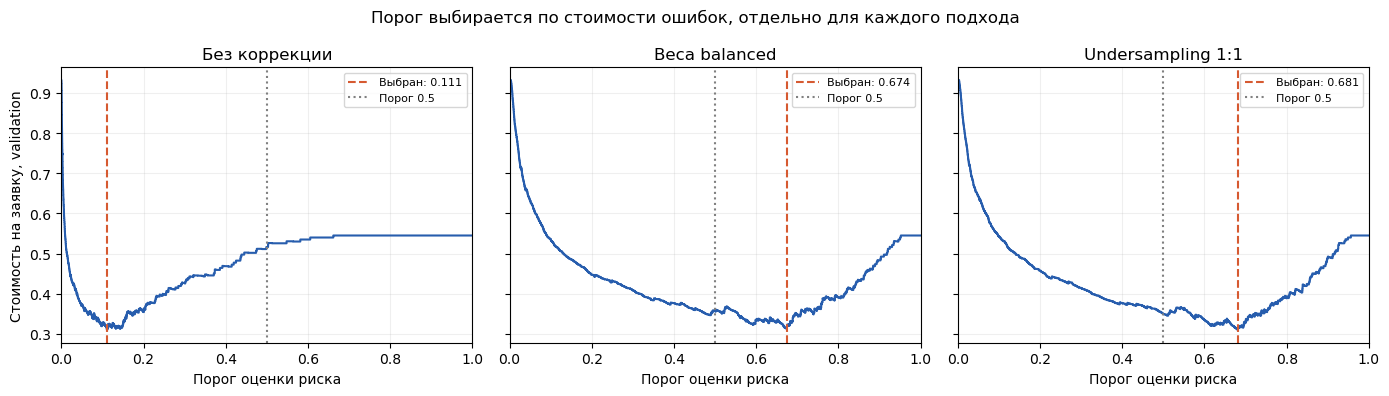

In [27]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, name in zip(axes, method_order):
    curve = threshold_curves[name]
# После максимальной оценки все заявки одобряются, стоимость далее постоянна.
    plot_curve = pd.concat([curve, curve.tail(1).assign(threshold=1.0)], ignore_index=True)
    ax.step(plot_curve['threshold'], plot_curve['cost_per_application'], where='pre', color='#275DAD')
    ax.axvline(chosen_thresholds[name], color='#D65A31', linestyle='--',
               label=f'Выбран: {chosen_thresholds[name]:.3f}')
    ax.axvline(0.5, color='gray', linestyle=':', label='Порог 0.5')
    ax.set(title=name, xlabel='Порог оценки риска', xlim=(0, 1))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Стоимость на заявку, validation')
fig.suptitle('Порог выбирается по стоимости ошибок, отдельно для каждого подхода')
fig.tight_layout()
plt.show()


### 6.1. Итоговая оценка на test
На одинаковых тестовых заявках считаем метрики действующего правила, одобрения всех,
логистической регрессии со всеми признаками при 0.5 и каждого подхода к дисбалансу
при порогах, уже выбранных на validation. Для основной модели также показываем порог 0.5.
Победителя по этой таблице **не переопределяем**: он уже выбран на validation.


In [28]:
test_rule = current_rule(X_test)
# вводим нулевую матрицу  
zero_test = np.zeros(len(y_test), dtype=int)
test_scores = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}
test_prob_all = logreg_all.predict_proba(X_test)[:, 1]
test_rows = {
    'Одобрить всех': full_metrics(y_test, zero_test, zero_test),
    'Действующее правило': full_metrics(y_test, test_rule, test_rule),
    'ЛР: все признаки, 0.5': full_metrics(y_test, test_prob_all >= 0.5, test_prob_all),
}
for name, scores in test_scores.items():
    test_rows[name + ' / свой порог'] = full_metrics(y_test, scores >= chosen_thresholds[name], scores)
final_name = selected_method + ' / свой порог'
test_score = test_scores[selected_method]
test_reject = (test_score >= best_threshold).astype(int)
test_rows['Выбранная модель / 0.5'] = full_metrics(y_test, test_score >= 0.5, test_score)
test_comparison = pd.DataFrame.from_dict(test_rows, orient='index')
print('Заявок test:', len(y_test), '| Дефолтов:', int(y_test.sum()))
print('Основная модель:', final_name, '| Порог:', round(best_threshold, 6))
print_comparison(test_comparison)

for name, decisions in [('Действующее правило', test_rule), (final_name, test_reject)]:
    matrix = pd.DataFrame(confusion_matrix(y_test, decisions, labels=[0, 1]),
        index=['Факт: без дефолта', 'Факт: дефолт'],
        columns=['Решение: одобрить', 'Решение: отказать'])
    print('\n' + name)
    print(matrix.to_string())
test_predictions = pd.DataFrame({
    'client_id': client_ids.loc[X_test.index], 'default': y_test,
    'risk_score': test_score, 'rule_reject': test_rule, 'model_reject': test_reject,
}, index=X_test.index)
assert test_predictions['client_id'].is_unique
assert np.isfinite(test_score).all()


Заявок test: 1600 | Дефолтов: 108
Основная модель: Без коррекции / свой порог | Порог: 0.111204
Качество (доли от 0 до 1):
                                accuracy  balanced_accuracy  precision  recall      F1  ROC_AUC      AP
Одобрить всех                     0.9325             0.5000     0.0000  0.0000  0.0000   0.5000  0.0675
Действующее правило               0.5812             0.7497     0.1332  0.9444  0.2334   0.7497  0.1295
ЛР: все признаки, 0.5             0.9281             0.5148     0.2667  0.0370  0.0650   0.8481  0.2390
Без коррекции / свой порог        0.7950             0.7612     0.2074  0.7222  0.3223   0.8546  0.2670
Веса balanced / свой порог        0.8194             0.7571     0.2249  0.6852  0.3387   0.8489  0.2648
Undersampling 1:1 / свой порог    0.8112             0.7485     0.2147  0.6759  0.3259   0.8485  0.2504
Выбранная модель / 0.5            0.9319             0.5168     0.4444  0.0370  0.0684   0.8546  0.2670

Ошибки и экономика (доля одобрений — от 0 до

## 7. Факторы риска: сила связи и направление влияния
Используем два дополняющих способа интерпретации выбранной модели:

1. **Permutation importance по исходным колонкам:** случайно перемешиваем один признак
   на validation и измеряем снижение AP. Чем больше падение, тем сильнее модель зависит
   от этой информации. Все категории одного признака меняются согласованно, поскольку
   перемешивание происходит до One-Hot Encoding. Повторяем 15 раз, показываем среднее и std.
2. **Коэффициенты и отношения шансов:** показывают направление связи при прочих равных.
   Для числовых признаков считаем отношение шансов для понятного изменения в исходных единицах.

Важность не доказывает причинность. Коррелирующие признаки могут заменять друг друга;
их индивидуальная важность может оказаться заниженной. Отрицательная важность может
возникнуть из-за случайности или переобучения. Std повторов — разброс перемешиваний,
а не доверительный интервал для всей популяции. Этот анализ не используется для нового
отбора или переобучения после теста. Исключённые ранее потенциальные утечки не анализируем как факторы риска.


Важность исходных признаков на validation:
             feature                        название  AP_drop_mean  AP_drop_std
      debt_to_income               Долговая нагрузка       0.22093      0.01735
  past_delinquencies               Прошлые просрочки       0.16346      0.01738
              income                           Доход       0.05428      0.01574
  credit_utilization Использование кредитного лимита       0.02804      0.01104
credit_history_years         Длина кредитной истории       0.01062      0.00622
    loan_term_months                    Срок кредита       0.00325      0.00524
                 age                         Возраст       0.00000      0.00000
    employment_years                     Стаж работы       0.00000      0.00000
           education                     Образование       0.00000      0.00000
             housing                           Жильё       0.00000      0.00000
   open_credit_lines        Открытые кредитные линии       0.00000      0.000

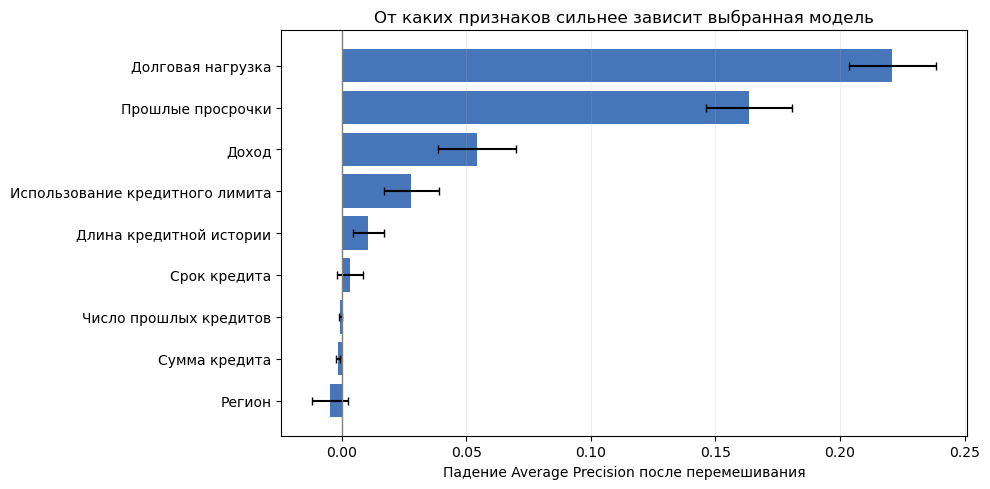

In [29]:
risk_labels = {
    'age': 'Возраст', 'income': 'Доход', 'employment_years': 'Стаж работы',
    'education': 'Образование', 'region': 'Регион', 'housing': 'Жильё',
    'credit_history_years': 'Длина кредитной истории', 'n_prev_loans': 'Число прошлых кредитов',
    'past_delinquencies': 'Прошлые просрочки', 'credit_utilization': 'Использование кредитного лимита',
    'open_credit_lines': 'Открытые кредитные линии', 'loan_amount': 'Сумма кредита',
    'loan_term_months': 'Срок кредита', 'debt_to_income': 'Долговая нагрузка',
    'interest_rate': 'Процентная ставка',
}
perm = permutation_importance(final_model, X_valid, y_valid,
    scoring='average_precision', n_repeats=15, random_state=SEED, n_jobs=1)
risk_importance = pd.DataFrame({
    'feature': X_valid.columns,
    'название': [risk_labels.get(c, c) for c in X_valid.columns],
    'AP_drop_mean': perm.importances_mean,
    'AP_drop_std': perm.importances_std,
}).sort_values('AP_drop_mean', ascending=False)
print('Важность исходных признаков на validation:')
print(risk_importance.round(5).to_string(index=False))

top_plot = risk_importance[risk_importance.AP_drop_mean.abs() > 1e-12].head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_plot['название'], top_plot['AP_drop_mean'], xerr=top_plot['AP_drop_std'],
        color='#275DAD', alpha=0.85, capsize=3)
ax.axvline(0, color='gray', linewidth=1)
ax.set(xlabel='Падение Average Precision после перемешивания',
       title='От каких признаков сильнее зависит выбранная модель')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
plt.show()

### 7.1. Направление связи: коэффициенты и отношения шансов
Логистическая регрессия моделирует логарифм шансов `log(p / (1 − p))`.
Для исходного числового признака, масштабированного `RobustScaler`, при изменении на `Δx`:

\[
OR = \exp\left(\beta\,\frac{\Delta x}{scale}\right).
\]

`scale` берётся из обученного scaler. OR больше 1 означает рост шансов дефолта,
меньше 1 — снижение. **Рост шансов вдвое не равен росту вероятности вдвое.**
Для чисел направление рассматривается при неизменных остальных признаках и индикаторах пропусков.
Шаги изменения задаём явно; доход и сумма кредита указаны в денежных единицах файла,
поскольку валюта в описании не приведена.

Для категорий сравниваем две реальные категории: `OR = exp(β_category − β_reference)`.
Самый частый уровень в train используется как точка сравнения, а не как «эталон надёжности».
При полном One-Hot Encoding отдельный коэффициент без сравнения с другим уровнем
не следует трактовать как эффект переключения категории.

Коэффициенты после взвешивания или undersampling характеризуют модель на изменённом
обучающем распределении. Даже в обычной модели это условные ассоциации, не доказанные
причины дефолта. Нулевой эффект исключённого признака означает, что модель его не использует,
а не что такой фактор не имеет значения в реальности.


In [31]:
final_preprocessor = final_model.named_steps['preprocess']
final_selector = final_model.named_steps['select']
final_names = final_preprocessor.get_feature_names_out()
final_selected = final_names[final_selector.get_support()]
final_beta = pd.Series(final_model.named_steps['model'].coef_[0], index=final_selected)

numeric_transformer = final_preprocessor.named_transformers_['num']
numeric_names = numeric_transformer.get_feature_names_out(num_features)
scale_by_name = dict(zip(numeric_names, numeric_transformer.named_steps['scaler'].scale_))
steps = {'age': 5, 'income': 10000, 'employment_years': 1,
         'credit_history_years': 1, 'n_prev_loans': 1, 'past_delinquencies': 1,
         'credit_utilization': 0.1, 'open_credit_lines': 1, 'loan_amount': 100000,
         'loan_term_months': 12, 'debt_to_income': 0.1, 'interest_rate': 1}
numeric_risk_rows = []
for col in num_features:
    name = 'num__' + col
    if name not in final_beta.index:
        continue
    beta = float(final_beta[name])
    delta = steps.get(col, 1)
    odds_ratio = float(np.exp(beta * delta / scale_by_name[col]))
    numeric_risk_rows.append({'feature': col, 'название': risk_labels.get(col, col),
        'изменение': delta, 'коэффициент': beta, 'OR': odds_ratio,
        'направление': 'рост риска' if beta > 0 else 'снижение риска' if beta < 0 else 'нет эффекта'})
numeric_risk = pd.DataFrame(numeric_risk_rows).set_index('feature')
numeric_risk = numeric_risk.join(risk_importance.set_index('feature')['AP_drop_mean'])
numeric_risk = numeric_risk.sort_values('AP_drop_mean', ascending=False)
print('Числовые признаки: направление и отношение шансов на указанный шаг:')
print(numeric_risk.round(4).to_string())

encoder_final = final_preprocessor.named_transformers_['cat'].named_steps['encoder']
category_rows = []
for col, categories in zip(cat_features, encoder_final.categories_):
    ref = X_train[col].dropna().mode().iloc[0]
    beta_ref = float(final_beta.get('cat__' + col + '_' + str(ref), 0.0))
    for category in categories:
        name = 'cat__' + col + '_' + str(category)
        # Выводим выбранные уровни и уровень сравнения для такого признака.
        group_selected = any(('cat__' + col + '_' + str(c)) in final_beta.index for c in categories)
        if not group_selected or (name not in final_beta.index and category != ref):
            continue
        beta = float(final_beta.get(name, 0.0))
        category_rows.append({'признак': col, 'категория': category, 'сравнение с': ref,
            'клиентов train': int((X_train[col] == category).sum()),
            'OR к категории сравнения': float(np.exp(beta - beta_ref))})
categorical_risk = pd.DataFrame(category_rows)
print('\nКатегориальные признаки:')
print(categorical_risk.round(4).to_string(index=False) if len(categorical_risk) else 'Категории не отобраны.')

print('\nСильнейшие связи в выбранной модели (по снижению AP на validation):')
for _, row in risk_importance[risk_importance.AP_drop_mean > 0].head(5).iterrows():
    col = row['feature']
    direction = numeric_risk.loc[col, 'направление'] if col in numeric_risk.index else 'зависит от категории'
    print(f"{row['название']}: ΔAP = {row['AP_drop_mean']:.4f}; {direction}.")


Числовые признаки: направление и отношение шансов на указанный шаг:
                                             название  изменение  коэффициент      OR     направление  AP_drop_mean
feature                                                                                                            
debt_to_income                      Долговая нагрузка        0.1       3.2073  2.3193      рост риска        0.2209
past_delinquencies                  Прошлые просрочки        1.0       0.4542  1.5750      рост риска        0.1635
income                                          Доход    10000.0      -0.4035  0.8996  снижение риска        0.0543
credit_utilization    Использование кредитного лимита        0.1       0.2970  1.1219      рост риска        0.0280
credit_history_years          Длина кредитной истории        1.0      -0.1491  0.9615  снижение риска        0.0106
loan_term_months                         Срок кредита       12.0      -0.1128  0.9452  снижение риска        0.0033
n_pr

### 7.2. Заключение по лабораторной работе
Числа ниже рассчитываются из результатов текущего запуска, а не вписаны вручную.
Выбранный подход определяется по validation; сравнение с правилом приводится на test.


In [32]:
rule_row = test_comparison.loc['Действующее правило']
model_row = test_comparison.loc[final_name]
cost_delta = rule_row.cost_8FN_FP - model_row.cost_8FN_FP
print(f'После отбора оставлено {len(final_selected)} из {len(final_names)} признаков.')
print(f'Выбран подход: {selected_method}; порог: {best_threshold:.6f}.')
print(f'Стоимость правила: {int(rule_row.cost_8FN_FP)}; модели: {int(model_row.cost_8FN_FP)} у.е.')
if cost_delta > 0:
    print(f'Снижение стоимости на test: {int(cost_delta)} у.е. ({cost_delta / rule_row.cost_8FN_FP:.1%}).')
elif cost_delta < 0:
    print(f'Стоимость модели выше правила на {-int(cost_delta)} у.е.; замена не подтверждается этой оценкой.')
else:
    print('Стоимость модели и правила одинакова.')
for name in ['Действующее правило', final_name]:
    row = test_comparison.loc[name]
    print(f'{name}: одобрено {row.approval_rate:.1%}; выявлено {row.recall:.1%} дефолтов; '
          f'ошибочных отказов {int(row.FP)}; пропущенных дефолтов {int(row.FN)}.')
print('Главный компромисс — число хороших клиентов, которым отказали, против числа пропущенных дефолтов.')
print('Подходы дали близкую стоимость на validation; устойчивость сравнения требует повторных разбиений.')
lower_test = [name for name in method_order
              if test_comparison.loc[name + ' / свой порог', 'cost_8FN_FP'] < model_row.cost_8FN_FP]
if lower_test:
    print('На test меньшая стоимость у: ' + ', '.join(lower_test) + '. '
          'Выбор по validation сохраняем: перевыбор по test нарушил бы протокол оценки.')
print('Факторы риска объясняют связи в модели, но не причинное влияние и не гарантируют повторение результата.')
print('Оценка по одному разбиению не доказывает экономию на будущих заявках.')


После отбора оставлено 10 из 49 признаков.
Выбран подход: Без коррекции; порог: 0.111204.
Стоимость правила: 712; модели: 538 у.е.
Снижение стоимости на test: 174 у.е. (24.4%).
Действующее правило: одобрено 52.1%; выявлено 94.4% дефолтов; ошибочных отказов 664; пропущенных дефолтов 6.
Без коррекции / свой порог: одобрено 76.5%; выявлено 72.2% дефолтов; ошибочных отказов 298; пропущенных дефолтов 30.
Главный компромисс — число хороших клиентов, которым отказали, против числа пропущенных дефолтов.
Подходы дали близкую стоимость на validation; устойчивость сравнения требует повторных разбиений.
На test меньшая стоимость у: Веса balanced. Выбор по validation сохраняем: перевыбор по test нарушил бы протокол оценки.
Факторы риска объясняют связи в модели, но не причинное влияние и не гарантируют повторение результата.
Оценка по одному разбиению не доказывает экономию на будущих заявках.


### Всем спасибо, хорошего дня!

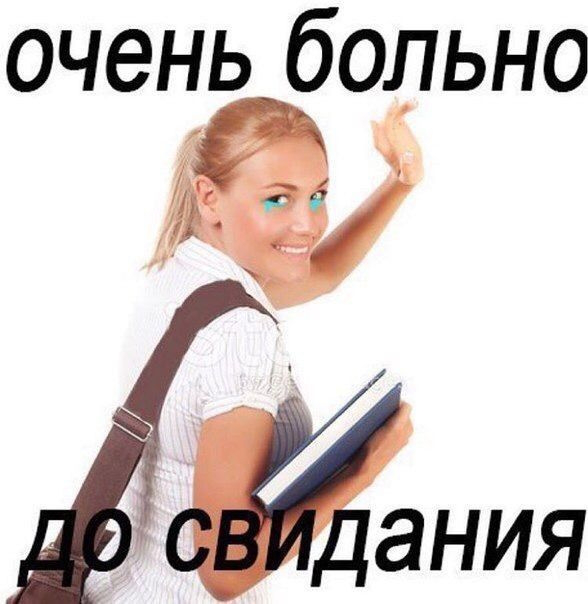

In [35]:
img = Image.open("на_улице_rain_в_душе_pain.jpg")

img